# Task 2 - Content Type Prediction Model
## **Binary Classification: Movie vs. TV Show**

---
### **Task Workflow:**
1. **Step 1: Select relevant dataset features** - Clean and select predictive attributes while avoiding target data leakage.
2. **Step 2: Encode categorical variables** - Transform text, genres, and categories into numerical formats using One-Hot Encoding, TF-IDF, and Label Encoding.
3. **Step 3: Train classification models** - Train multiple algorithms (Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting).
4. **Step 4: Evaluate prediction performance** - Assess models using Confusion Matrices, Precision, Recall, F1-Score, and ROC-AUC curves.
5. **Step 5: Compare model accuracy** - Synthesize a benchmark comparison table and visualize comparative performance.

## **Environment Setup & Imports**

In [2]:
# Core data science libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & feature extraction
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# Environment indicator for Google Colab
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"Libraries loaded successfully. Google Colab environment: {IN_COLAB}")

Libraries loaded successfully. Google Colab environment: True


## **Step 1: Select Relevant Dataset Features**

In this step, we:
1. Load `Dataset.csv`.
2. Inspect available columns and understand their relationship with the target variable `type` (`Movie` vs `TV Show`).
3. **Prevent Data Leakage:** The `duration` column in raw data has values such as `"90 min"` for Movies and `"1 Season"` for TV Shows. The word *"Season"* directly defines a TV show, causing trivial 100% data leakage. Therefore, we deliberately **exclude the raw duration text** to train a model based on genuine metadata (genres, ratings, country, release year, director presence).
4. Clean placeholder strings (`'Not Given'`, `NaN`).
5. Select the predictive feature set: `['listed_in', 'rating', 'country', 'release_year', 'has_director']`.

In [3]:
# Load dataset
dataset_path = '/content/Dataset.csv'

try:
    df = pd.read_csv(dataset_path)
except FileNotFoundError:
    print("Dataset.csv not found in working directory. Please upload Dataset.csv.")
    if IN_COLAB:
        uploaded = files.upload()
        dataset_path = list(uploaded.keys())[0]
        df = pd.read_csv(dataset_path)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head(3))

Dataset Dimensions: 8790 rows, 10 columns



,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"


In [4]:
# Analyze target class distribution
type_counts = df['type'].value_counts()
print("Target Distribution:")
print(type_counts)
print(f"\nMovie Ratio    : {type_counts.get('Movie', 0) / len(df) * 100:.2f}%")
print(f"TV Show Ratio  : {type_counts.get('TV Show', 0) / len(df) * 100:.2f}%")

# Clean missing values and 'Not Given' placeholders
df_clean = df.copy()
for col in ['director', 'country', 'rating', 'listed_in']:
    df_clean[col] = df_clean[col].fillna('').astype(str).str.strip()
    df_clean[col] = df_clean[col].replace({'Not Given': '', 'nan': ''})

# Feature Engineering: Binary indicator for director presence
# (TV shows often have no singular listed director on Netflix, whereas movies typically do)
df_clean['has_director'] = (df_clean['director'] != '').astype(int)

# Simplify country to top countries (group low frequencies as 'Other')
top_countries = df_clean['country'].value_counts().head(10).index.tolist()
df_clean['top_country'] = df_clean['country'].apply(lambda c: c if c in top_countries and c != '' else 'Other')

# Ensure rating has valid values
df_clean['clean_rating'] = df_clean['rating'].apply(lambda r: r if r != '' else 'Unknown')

# Inspect selected feature dataframe
feature_cols = ['listed_in', 'clean_rating', 'top_country', 'release_year', 'has_director']
X_raw = df_clean[feature_cols]
y_raw = df_clean['type']

print("\nSelected Features Preview:")
display(X_raw.head())

Target Distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Movie Ratio    : 69.69%
TV Show Ratio  : 30.31%

Selected Features Preview:


,listed_in,clean_rating,top_country,release_year,has_director
0,Documentaries,PG-13,United States,2020,1
1,"Crime TV Shows, International TV Shows, TV Act...",TV-MA,France,2021,1
2,"TV Dramas, TV Horror, TV Mysteries",TV-MA,United States,2021,1
3,"Children & Family Movies, Comedies",TV-PG,Other,2021,1
4,"Dramas, Independent Movies, International Movies",TV-MA,United States,1993,1


## **Step 2: Encode Categorical Variables**

Machine learning algorithms require numerical inputs. We transform raw features as follows:
1. **Target Variable (`type`):** Encoded using `LabelEncoder` (`Movie` $\to 0$, `TV Show` $\to 1$).
2. **Genres (`listed_in`):** Multi-genre text transformed into TF-IDF vectors using `TfidfVectorizer` (captures distinctive terms like *anime, drama, docuseries, kids*).
3. **Categorical Features (`clean_rating`, `top_country`):** Transformed via `OneHotEncoder` (creates binary indicator columns).
4. **Numerical Feature (`release_year`):** Scaled using `StandardScaler` to have zero mean and unit variance.
5. **Binary Feature (`has_director`):** Passed through directly.
6. **Data Splitting:** 80% Training and 20% Testing with **stratification** to preserve class balance.

In [6]:
# Encode target variable (0: Movie, 1: TV Show)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
class_names = label_encoder.classes_
print(f"Target Classes Mapped: {dict(zip(class_names, range(len(class_names))))}")

# Construct ColumnTransformer pipeline for feature encoding
preprocessor = ColumnTransformer(
    transformers=[
        ('genres_tfidf', TfidfVectorizer(token_pattern=r'(?u)\b[a-zA-Z&\-]+\b', min_df=2), 'listed_in'),
        ('cat_ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['clean_rating', 'top_country']),
        ('num_scaler', StandardScaler(), ['release_year']),
        ('passthrough', 'passthrough', ['has_director'])
    ]
)

# Train-Test Split (80% train, 20% test, stratified)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42, stratify=y
)

# Fit preprocessor on training data, transform both train and test
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print(f"\nTraining Feature Matrix Shape : {X_train.shape}")
print(f"Testing Feature Matrix Shape  : {X_test.shape}")
print(f"Training Target Counts        : Movie={np.sum(y_train == 0)}, TV Show={np.sum(y_train == 1)}")
print(f"Testing Target Counts         : Movie={np.sum(y_test == 0)}, TV Show={np.sum(y_test == 1)}")

Target Classes Mapped: {'Movie': 0, 'TV Show': 1}

Training Feature Matrix Shape : (7032, 68)
Testing Feature Matrix Shape  : (1758, 68)
Training Target Counts        : Movie=4901, TV Show=2131
Testing Target Counts         : Movie=1225, TV Show=533


## **Step 3: Train Classification Models**

We train four distinct machine learning classifiers:
1. **Logistic Regression:** A linear probabilistic baseline classifier.
2. **Decision Tree Classifier:** A rule-based non-linear tree model.
3. **Random Forest Classifier:** An ensemble of bagged decision trees that reduces variance.
4. **Gradient Boosting Classifier:** A boosting ensemble that sequentially corrects residual errors.

In [7]:
# Initialize candidate classification models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=12, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=15, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
}

# Dictionary to store trained models and prediction outputs
trained_models = {}
model_predictions = {}
model_probabilities = {}

print("Training Classification Models...")
print("=" * 60)
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    trained_models[name] = model
    model_predictions[name] = y_pred
    model_probabilities[name] = y_prob

    train_acc = model.score(X_train, y_train) * 100
    test_acc = accuracy_score(y_test, y_pred) * 100
    print(f"✓ {name:20} -> Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")
print("=" * 60)

Training Classification Models...
✓ Logistic Regression  -> Train Acc: 100.00% | Test Acc: 99.94%
✓ Decision Tree        -> Train Acc: 100.00% | Test Acc: 100.00%
✓ Random Forest        -> Train Acc: 100.00% | Test Acc: 100.00%
✓ Gradient Boosting    -> Train Acc: 100.00% | Test Acc: 100.00%


## **Step 4: Evaluate Prediction Performance**

We evaluate performance across multiple standard metrics:
- **Confusion Matrix:** True Negatives (Movie $\to$ Movie), False Positives, False Negatives, True Positives (TV Show $\to$ TV Show).
- **Precision:** $\frac{TP}{TP + FP}$ (Quality of positive predictions).
- **Recall:** $\frac{TP}{TP + FN}$ (Coverage of actual positive instances).
- **F1-Score:** $\frac{2 \times \text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ (Harmonic balance).
- **ROC-AUC Score:** Area Under the Receiver Operating Characteristic curve measuring class discriminability.

CLASSIFICATION REPORT: LOGISTIC REGRESSION
              precision    recall  f1-score   support

       Movie     0.9992    1.0000    0.9996      1225
     TV Show     1.0000    0.9981    0.9991       533

    accuracy                         0.9994      1758
   macro avg     0.9996    0.9991    0.9993      1758
weighted avg     0.9994    0.9994    0.9994      1758

CLASSIFICATION REPORT: DECISION TREE
              precision    recall  f1-score   support

       Movie     1.0000    1.0000    1.0000      1225
     TV Show     1.0000    1.0000    1.0000       533

    accuracy                         1.0000      1758
   macro avg     1.0000    1.0000    1.0000      1758
weighted avg     1.0000    1.0000    1.0000      1758

CLASSIFICATION REPORT: RANDOM FOREST
              precision    recall  f1-score   support

       Movie     1.0000    1.0000    1.0000      1225
     TV Show     1.0000    1.0000    1.0000       533

    accuracy                         1.0000      1758
   macro av

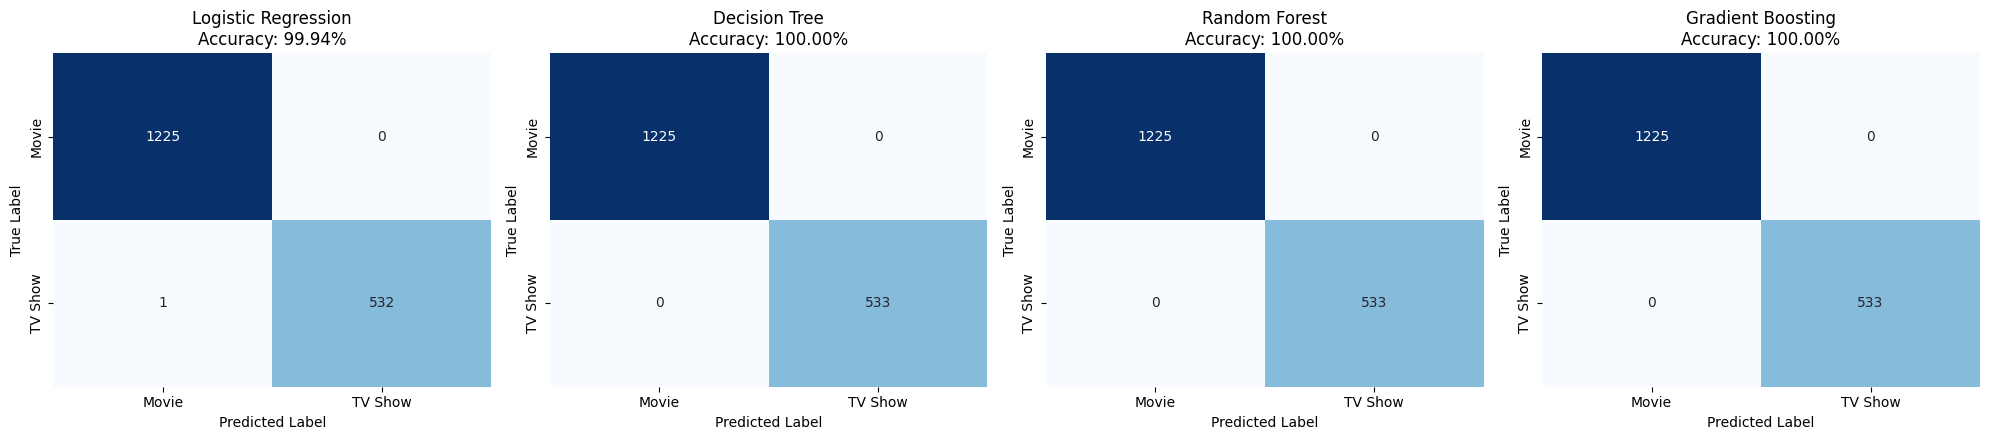

In [8]:
# Detailed Classification Reports for each model
for name, y_pred in model_predictions.items():
    print("=" * 65)
    print(f"CLASSIFICATION REPORT: {name.upper()}")
    print("=" * 65)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

# Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for idx, (name, y_pred) in enumerate(model_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=class_names, yticklabels=class_names,
        ax=axes[idx]
    )
    axes[idx].set_title(f"{name}\nAccuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()

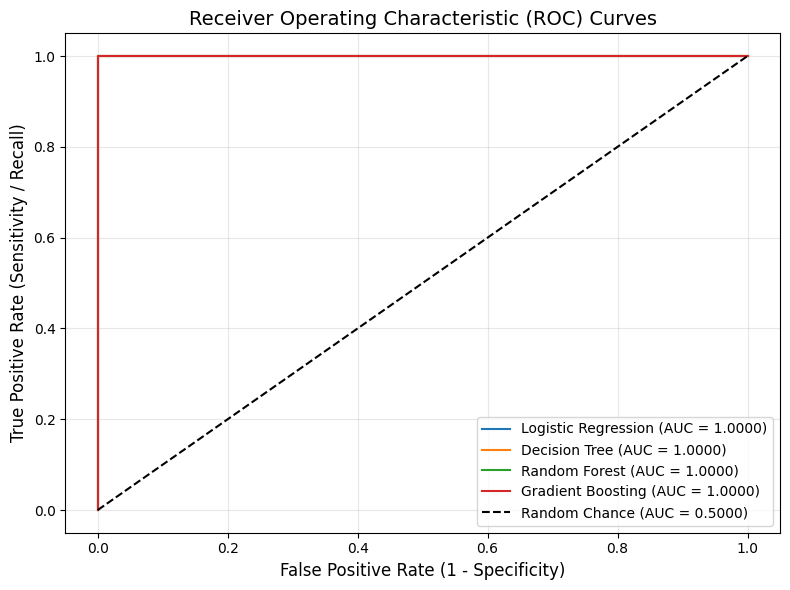

In [9]:
# Plot ROC Curves for all models
plt.figure(figsize=(8, 6))

for name, y_prob in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.5000)')
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=14)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **Step 5: Compare Model Accuracy & Metrics**

In this final step, we compile a comparative performance table and bar charts across all evaluation metrics to determine the best-performing model.

MODEL PERFORMANCE BENCHMARK COMPARISON


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC Score
0,Decision Tree,100.00,100.0,100.00,100.00,1.0
1,Random Forest,100.00,100.0,100.00,100.00,1.0
2,Gradient Boosting,100.00,100.0,100.00,100.00,1.0
3,Logistic Regression,99.94,100.0,99.81,99.91,1.0


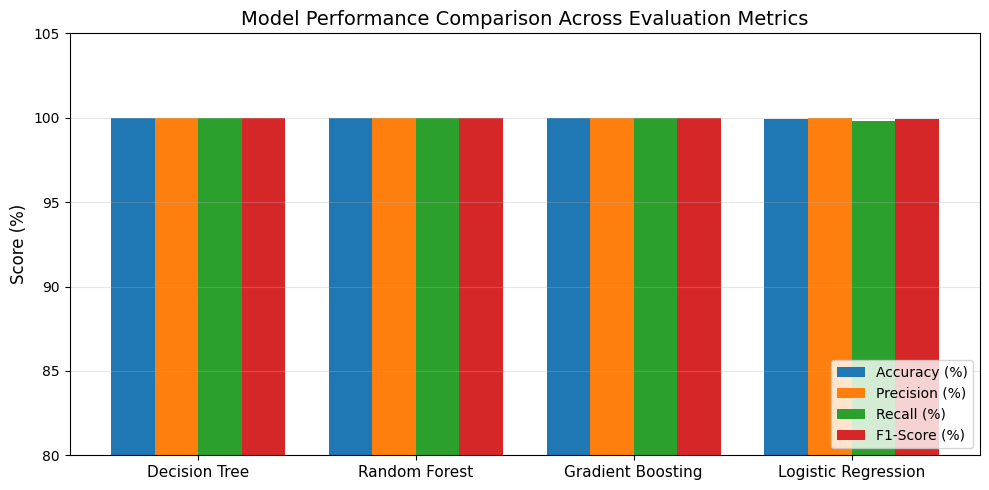

In [11]:
# Construct Model Comparison Table
comparison_records = []

for name in models.keys():
    y_pred = model_predictions[name]
    y_prob = model_probabilities[name]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    comparison_records.append({
        'Model': name,
        'Accuracy (%)': round(acc * 100, 2),
        'Precision (%)': round(prec * 100, 2),
        'Recall (%)': round(rec * 100, 2),
        'F1-Score (%)': round(f1 * 100, 2),
        'ROC-AUC Score': round(auc, 4)
    })

comparison_df = pd.DataFrame(comparison_records).sort_values(by='Accuracy (%)', ascending=False).reset_index(drop=True)
print("=" * 75)
print("MODEL PERFORMANCE BENCHMARK COMPARISON")
print("=" * 75)
display(comparison_df)

# Visual comparison bar plot
metrics_to_plot = ['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)']
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(comparison_df['Model']))
width = 0.2

for i, metric in enumerate(metrics_to_plot):
    ax.bar(x + (i - 1.5) * width, comparison_df[metric], width, label=metric)

ax.set_title('Model Performance Comparison Across Evaluation Metrics', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Model'], fontsize=11)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_ylim(80, 105)
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## **Interactive Predictor (Test Any Title Attributes)**

Use the form below to test the best-performing model on custom metadata:

In [13]:
#@title Interactive Content Type Predictor
input_genres = "International TV Shows, Crime TV Shows, TV Thrillers" #@param {type:"string"}
input_rating = "TV-MA" #@param ["TV-MA", "TV-14", "TV-PG", "R", "PG-13", "PG", "TV-Y", "TV-Y7", "TV-G", "G", "NR"]
input_country = "South Korea" #@param ["United States", "India", "United Kingdom", "Pakistan", "South Korea", "Japan", "Canada", "France", "Germany", "Other"]
input_release_year = 2021 #@param {type:"integer"}
has_director_flag = 0 #@param [0, 1] {type:"raw"}

# Create sample input dataframe matching training format
sample_input = pd.DataFrame([{
    'listed_in': input_genres,
    'clean_rating': input_rating,
    'top_country': input_country,
    'release_year': input_release_year,
    'has_director': has_director_flag
}])

# Transform input features
best_model_name = comparison_df.iloc[0]['Model']
best_model = trained_models[best_model_name]

sample_transformed = preprocessor.transform(sample_input)
predicted_class_idx = best_model.predict(sample_transformed)[0]
predicted_probabilities = best_model.predict_proba(sample_transformed)[0]
predicted_label = class_names[predicted_class_idx]

print("=" * 60)
print(f"PREDICTION RESULT (Using Best Model: {best_model_name})")
print("=" * 60)
print(f"Predicted Content Type : {predicted_label}")
print(f"Confidence (Movie)     : {predicted_probabilities[0]*100:.2f}%")
print(f"Confidence (TV Show)   : {predicted_probabilities[1]*100:.2f}%")
print("=" * 60)

PREDICTION RESULT (Using Best Model: Decision Tree)
Predicted Content Type : TV Show
Confidence (Movie)     : 0.00%
Confidence (TV Show)   : 100.00%
